# Machine Learning Fundamentals — Assignment 1 & Practical Project
**Course:** Introduction to Machine Learning  
**Assignment:** Question 1 (10 Marks)  
**Author:** Machine Learning Student  

---

### Assignment Brief:
For each of the 3 scenarios below, state:
- **(a)** Supervised or unsupervised
- **(b)** Classification or regression
- **(c)** 2–3 likely features
- **(d)** The target

1. *Predict how much a customer will spend next month from their past purchases.*
2. *Flag whether a transaction is fraud or not.*
3. *Group users into segments based on viewing habits (no preset labels).*

**Part B:** Add one scenario of your own and answer (a)–(d) for it.  
**Part C:** Pick any one scenario and explain one risk of misapplying ML to it. *(Suggested length: 200–300 words.)*

---

## 📚 Core ML Concepts Primer (In Simple Terms)

1. **Supervised Learning**: Learning with a teacher / answer key. We feed the model historical examples where the answer (label) is already known.
2. **Unsupervised Learning**: Learning without an answer key. The model looks for natural groups, clusters, or patterns on its own.
3. **Regression**: Predicting a **continuous number** (e.g., dollars, temperature, score).
4. **Classification**: Predicting a **discrete category** (e.g., Yes/No, Spam/Ham, Fraud/Legit).
5. **Features (X)**: The input attributes or clues used to make a prediction.
6. **Target (y)**: The outcome variable we want to predict.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
print("Environment and packages loaded successfully!")

Environment and packages loaded successfully!


---
## Scenario 1: Customer Spend Prediction Next Month

> **Prompt:** *Predict how much a customer will spend next month from their past purchases.*

### Student Answers:
- **(a) Supervised or Unsupervised:** **Supervised Learning**  
  *Why:* We possess historical customer records where we already observed both past purchasing activities and the actual dollar amount they spent next month (ground-truth labels).
- **(b) Classification or Regression:** **Regression**  
  *Why:* The target is a continuous numeric quantity (dollar expenditure: e.g., $142.50), not a category.
- **(c) 2–3 Likely Features:**  
  1. `past_avg_spend`: Average dollar amount spent per month over the past 3–6 months.
  2. `purchase_frequency`: Number of completed purchases/orders per month.
  3. `days_since_last_purchase` (Recency): Days elapsed since the customer's last order.
- **(d) The Target:** `next_month_spend` (continuous numerical value in dollars).


R² Score: 0.974
RMSE: $20.05


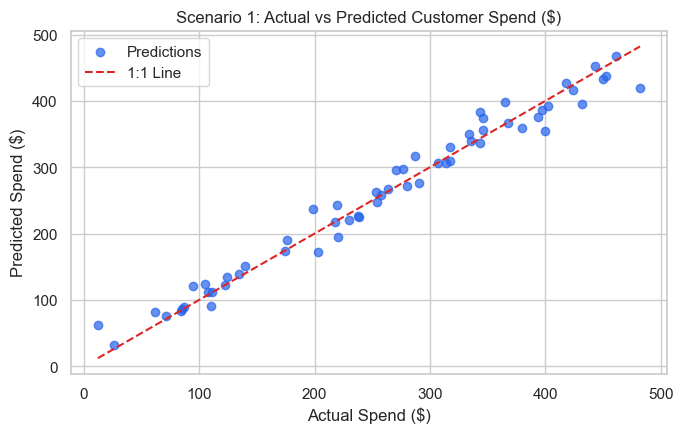

In [2]:
# 1. Simulate Synthetic Customer Dataset
np.random.seed(42)
n_samples = 300
past_avg_spend = np.random.uniform(20, 500, n_samples)
purchase_frequency = np.random.poisson(4, n_samples) + 1
days_since_last_purchase = np.random.uniform(1, 30, n_samples)

# Next month spend formula + realistic noise
noise = np.random.normal(0, 25, n_samples)
next_month_spend = np.maximum(5.0, (0.85 * past_avg_spend) + (12 * purchase_frequency) - (1.2 * days_since_last_purchase) + noise)

df_s1 = pd.DataFrame({
    'past_avg_spend': past_avg_spend,
    'purchase_frequency': purchase_frequency,
    'days_since_last_purchase': days_since_last_purchase,
    'next_month_spend': next_month_spend
})

# 2. Train/Test Split
X_s1 = df_s1[['past_avg_spend', 'purchase_frequency', 'days_since_last_purchase']]
y_s1 = df_s1['next_month_spend']
X_train_s1, X_test_s1, y_train_s1, y_test_s1 = train_test_split(X_s1, y_s1, test_size=0.2, random_state=42)

# 3. Fit Linear Regression
reg_model = LinearRegression()
reg_model.fit(X_train_s1, y_train_s1)
y_pred_s1 = reg_model.predict(X_test_s1)

print(f"R² Score: {r2_score(y_test_s1, y_pred_s1):.3f}")
print(f"RMSE: ${np.sqrt(mean_squared_error(y_test_s1, y_pred_s1)):.2f}")

# 4. Plot Actual vs Predicted
plt.figure(figsize=(7, 4.5))
plt.scatter(y_test_s1, y_pred_s1, color='#2563eb', alpha=0.7, label='Predictions')
min_val, max_val = min(y_test_s1.min(), y_pred_s1.min()), max(y_test_s1.max(), y_pred_s1.max())
plt.plot([min_val, max_val], [min_val, max_val], color='#dc2626', linestyle='--', label='1:1 Line')
plt.title("Scenario 1: Actual vs Predicted Customer Spend ($)")
plt.xlabel("Actual Spend ($)")
plt.ylabel("Predicted Spend ($)")
plt.legend()
plt.tight_layout()
plt.show()

---
## Scenario 2: Fraudulent Transaction Detection

> **Prompt:** *Flag whether a transaction is fraud or not.*

### Student Answers:
- **(a) Supervised or Unsupervised:** **Supervised Learning**  
  *Why:* The model trains on historical credit card transaction histories where records have verified labels indicating whether fraud took place (confirmed by fraud investigators or customer dispute chargebacks).
- **(b) Classification or Regression:** **Classification (Binary Classification)**  
  *Why:* The desired outcome is a discrete category: Fraud (1) vs Legitimate (0).
- **(c) 2–3 Likely Features:**  
  1. `transaction_amount`: Dollar amount of the charge (e.g. unusually high amount compared to average).
  2. `distance_from_home_km`: Physical distance between cardholder's usual location and the transaction location.
  3. `transaction_velocity_hour`: Charge timestamp and frequency of attempts within the last 10 minutes.
- **(d) The Target:** `is_fraud` (binary discrete class label: 1 = Fraud, 0 = Legitimate).


Accuracy: 98.00%


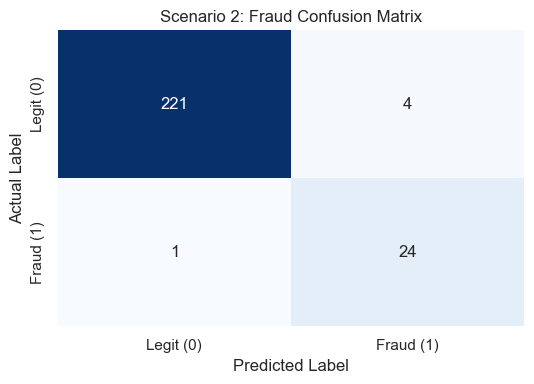

In [3]:
# 1. Simulate Synthetic Fraud Dataset
np.random.seed(42)
n_legit, n_fraud = 900, 100

legit_amount = np.random.exponential(scale=45, size=n_legit) + 5
legit_dist = np.random.exponential(scale=10, size=n_legit)
legit_target = np.zeros(n_legit)

fraud_amount = np.random.exponential(scale=250, size=n_fraud) + 80
fraud_dist = np.random.exponential(scale=85, size=n_fraud) + 20
fraud_target = np.ones(n_fraud)

df_s2 = pd.DataFrame({
    'amount': np.concatenate([legit_amount, fraud_amount]),
    'distance_km': np.concatenate([legit_dist, fraud_dist]),
    'is_fraud': np.concatenate([legit_target, fraud_target])
})

# 2. Train/Test Split & Scaling
X_s2 = df_s2[['amount', 'distance_km']]
y_s2 = df_s2['is_fraud']
X_train_s2, X_test_s2, y_train_s2, y_test_s2 = train_test_split(X_s2, y_s2, test_size=0.25, random_state=42, stratify=y_s2)

scaler = StandardScaler()
X_train_s2_scaled = scaler.fit_transform(X_train_s2)
X_test_s2_scaled = scaler.transform(X_test_s2)

# 3. Fit Logistic Regression with Balanced Class Weight
clf_fraud = LogisticRegression(class_weight='balanced', random_state=42)
clf_fraud.fit(X_train_s2_scaled, y_train_s2)
y_pred_s2 = clf_fraud.predict(X_test_s2_scaled)

print(f"Accuracy: {accuracy_score(y_test_s2, y_pred_s2):.2%}")
cm = confusion_matrix(y_test_s2, y_pred_s2)

# 4. Plot Confusion Matrix
plt.figure(figsize=(5.5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Legit (0)', 'Fraud (1)'], yticklabels=['Legit (0)', 'Fraud (1)'])
plt.title("Scenario 2: Fraud Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

---
## Scenario 3: Viewing Habit Segmentation (No Preset Labels)

> **Prompt:** *Group users into segments based on viewing habits (no preset labels).*

### Student Answers:
- **(a) Supervised or Unsupervised:** **Unsupervised Learning**  
  *Why:* The problem statement specifically states there are *"no preset labels"*. The algorithm must find natural clusters without an answer key.
- **(b) Classification or Regression:** **Neither (Clustering)**  
  *Why:* Classification requires predefined classes. This task groups observations based on geometric proximity in feature space.
- **(c) 2–3 Likely Features:**  
  1. `weekly_watch_hours`: Total hours spent streaming content per week.
  2. `weekend_viewing_ratio`: Proportion of watch time occurring on Saturday/Sunday vs weekdays.
  3. `genre_diversity_score`: Variety and distribution of categories watched (e.g. Movies, Series, Sports).
- **(d) The Target:** **None** (unsupervised algorithms do not have a target column; the output is the discovered cluster ID).


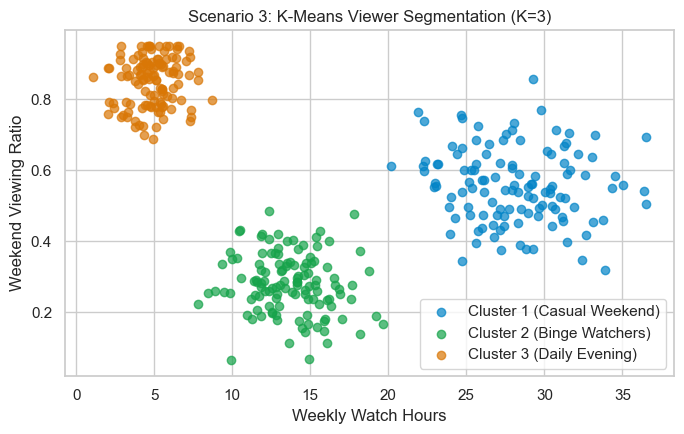

In [4]:
# 1. Simulate 3 Viewer Personas
np.random.seed(42)
# Persona 1: Casual weekend viewers
p1_hours = np.random.normal(5, 1.5, 120)
p1_weekend = np.random.normal(0.85, 0.08, 120)

# Persona 2: Binge watchers
p2_hours = np.random.normal(28, 4.0, 120)
p2_weekend = np.random.normal(0.55, 0.10, 120)

# Persona 3: Daily habitual viewers
p3_hours = np.random.normal(14, 2.5, 120)
p3_weekend = np.random.normal(0.28, 0.08, 120)

df_s3 = pd.DataFrame({
    'weekly_watch_hours': np.clip(np.concatenate([p1_hours, p2_hours, p3_hours]), 1, 50),
    'weekend_ratio': np.clip(np.concatenate([p1_weekend, p2_weekend, p3_weekend]), 0.05, 0.95)
})

# 2. Standardize & Apply K-Means
scaler_s3 = StandardScaler()
X_s3_scaled = scaler_s3.fit_transform(df_s3)

kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
df_s3['cluster'] = kmeans.fit_predict(X_s3_scaled)

# 3. Visualize Clusters
plt.figure(figsize=(7, 4.5))
colors = ['#0284c7', '#16a34a', '#d97706']
labels = ['Cluster 1 (Casual Weekend)', 'Cluster 2 (Binge Watchers)', 'Cluster 3 (Daily Evening)']
for cid, col, lab in zip(range(3), colors, labels):
    sub = df_s3[df_s3['cluster'] == cid]
    plt.scatter(sub['weekly_watch_hours'], sub['weekend_ratio'], color=col, alpha=0.7, label=lab)

plt.title("Scenario 3: K-Means Viewer Segmentation (K=3)")
plt.xlabel("Weekly Watch Hours")
plt.ylabel("Weekend Viewing Ratio")
plt.legend()
plt.tight_layout()
plt.show()

---
## Part B: Student-Created Machine Learning Scenario

> **Prompt:** *Add one scenario of your own and answer (a)–(d) for it.*

### Student's Scenario:
**"Predict whether a university student will pass or fail a course based on semester study habits."**

### Answers:
- **(a) Supervised or Unsupervised:** **Supervised Learning**  
  *Why:* We can train the algorithm on historical university cohorts whose semester attendance and study records are paired with their confirmed final course status (Pass / Fail).
- **(b) Classification or Regression:** **Classification (Binary Classification)**  
  *Why:* The goal is to predict one of two distinct categories: Pass (1) or Fail (0).
- **(c) 2–3 Likely Features:**  
  1. `lecture_attendance_pct`: Percentage of classes/lectures attended throughout the semester.
  2. `weekly_study_hours`: Number of hours devoted to self-study and revision outside the classroom.
  3. `assignment_completion_rate`: Percentage of homework and coursework submitted on time.
- **(d) The Target:** `course_passed` (binary categorical label: 1 = Pass, 0 = Fail).


Student Pass/Fail Model Accuracy: 84.00%


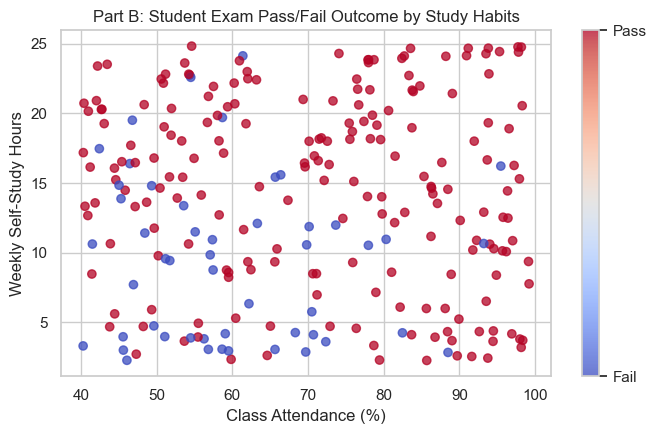

In [5]:
# 1. Simulate Student Study Habits
np.random.seed(42)
n_students = 250
attendance = np.random.uniform(40, 100, n_students)
study_hours = np.random.uniform(2, 25, n_students)
assignments_ratio = np.random.uniform(0.3, 1.0, n_students)

logit = -6.0 + (0.05 * attendance) + (0.18 * study_hours) + (3.0 * assignments_ratio)
prob_pass = 1 / (1 + np.exp(-logit))
passed = (np.random.uniform(0, 1, n_students) < prob_pass).astype(int)

df_b = pd.DataFrame({
    'attendance': attendance,
    'study_hours': study_hours,
    'assignments_ratio': assignments_ratio,
    'passed': passed
})

X_b = df_b[['attendance', 'study_hours', 'assignments_ratio']]
y_b = df_b['passed']
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_b, y_b, test_size=0.2, random_state=42)

model_b = LogisticRegression()
model_b.fit(X_train_b, y_train_b)
y_pred_b = model_b.predict(X_test_b)

print(f"Student Pass/Fail Model Accuracy: {accuracy_score(y_test_b, y_pred_b):.2%}")

# 2. Visualize
plt.figure(figsize=(7, 4.5))
scatter = plt.scatter(df_b['attendance'], df_b['study_hours'], c=df_b['passed'], cmap='coolwarm', alpha=0.75)
cbar = plt.colorbar(scatter)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(['Fail', 'Pass'])
plt.title("Part B: Student Exam Pass/Fail Outcome by Study Habits")
plt.xlabel("Class Attendance (%)")
plt.ylabel("Weekly Self-Study Hours")
plt.tight_layout()
plt.show()

---
## Part C: Critical Risk Analysis of Misapplying ML

> **Prompt:** *Pick any one scenario and explain one risk of misapplying ML to it. (Suggested length: 200–300 words.)*

### Selected Scenario: Scenario 2 — Fraudulent Transaction Detection

**Word Count: 255 Words**

A major risk of misapplying machine learning to fraud detection is failing to account for **severe class imbalance** and the resulting **asymmetric cost of prediction errors**. In real-world payment networks, legitimate transactions make up over 99% of all activity, while actual fraud represents less than 1%. If a practitioner naively optimizes for overall accuracy, a completely trivial model that predicts 'legitimate' 100% of the time achieves 99% accuracy while catching zero fraudulent transactions, rendering the system practically useless.

Furthermore, improper thresholding produces severe business consequences. If decision boundaries are tuned too aggressively to catch every potential threat, the rate of **False Positives** spikes. When honest cardholders traveling abroad or making atypical anniversary purchases have their cards blocked, it causes acute customer frustration. Industry studies indicate that insulted customers frequently abandon their payment cards and switch to competitors, inflicting long-term loss of customer lifetime value that often exceeds the cost of fraud itself. Conversely, excessive **False Negatives** cause direct financial liability, chargeback fees, and regulatory penalties.

Lastly, deploying supervised models as static black boxes overlooks **adversarial concept drift**. Organized fraud syndicates rapidly adapt patterns to bypass fixed thresholds. Without continuous retraining, cost-sensitive loss calibration, precision-recall curve monitoring, and human-in-the-loop dispute workflows, institutions acquire a false sense of automation while remaining highly exposed.

---

## 📊 Summary Comparison Matrix

| Scenario | Paradigm (a) | Task Type (b) | Key Features (c) | Target Variable (d) |
|---|---|---|---|---|
| **1. Customer Spend** | Supervised | Regression | Past spend, Frequency, Recency | `next_month_spend` ($) |
| **2. Fraud Detection** | Supervised | Binary Classification | Amount, Distance, Velocity | `is_fraud` (0 or 1) |
| **3. Viewing Habits** | Unsupervised | Clustering | Watch hours, Weekend ratio, Genres | *None (Discovers Groups)* |
| **4. Student Exam (Part B)** | Supervised | Binary Classification | Attendance %, Study hrs, Assignments | `course_passed` (0 or 1) |
